# [SOAI - AI Camp] - Palmer Penguins: EDA Walkthrough

**Dataset:** Palmer Penguins, 7 columns:
`species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex`.

**Goal of this notebook:** a nice and simple EDA pipeline that treats `species` as the prediction target.

**Contents**
1. Loading data (CSV and other formats)
2. Inspecting shape, types, ranges, missingness, duplicates
3. Summary statistics and distributions
4. Target distribution and relationships
5. Outliers, sampling bias, leakage, data quality
6. Conclusions

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

Very important before we start, the anatomy of a penguin bch tefehmou the feature names lol:

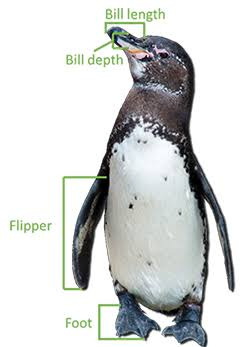

## 1. Loading the data

The dataset was loaded from the Seaborns library. You can also attach it as a CSV/xslx/SQL db/other formats, if you're quirky.

In [ ]:
df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


**Other common formats** (for reference, adapt the path):

```python
pd.read_csv("file.csv", sep=";", na_values=["NA", "?", "."], encoding="utf-8")  # custom separators / NA tokens
pd.read_excel("file.xlsx", sheet_name=0)                                         # needs openpyxl
pd.read_json("file.json", lines=False)
pd.read_parquet("file.parquet")                                                  # needs pyarrow
pd.read_sql("SELECT * FROM penguins", con)                                       # SQLAlchemy / sqlite3 connection
```

## 2. First inspection: shape, types, ranges, missingness, duplicates

In [ ]:
print("Shape:", df.shape)
print()
df.info()

Shape: (344, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [ ]:
df.dtypes.to_frame("dtype").join(df.nunique().to_frame("n_unique"))

,dtype,n_unique
species,object,3
island,object,3
bill_length_mm,float64,164
bill_depth_mm,float64,80
flipper_length_mm,float64,55
body_mass_g,float64,94
sex,object,2


In [ ]:
# Ranges for numeric columns, and exact levels for categorical columns
display(df.select_dtypes("number").agg(["min", "max"]).T)

for col in ["species", "island", "sex"]:
    print(f"\n{col}: {df[col].value_counts(dropna=False).to_dict()}")

,min,max
bill_length_mm,32.1,59.6
bill_depth_mm,13.1,21.5
flipper_length_mm,172.0,231.0
body_mass_g,2700.0,6300.0



species: {'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}

island: {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52}

sex: {'Male': 168, 'Female': 165, nan: 11}


### Missingness
Missing values are only useful to understand if we ask **where** they are and **why** they might be there.

In [ ]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(df) * 100).round(2)
display(missing)

,n_missing,pct
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


In [ ]:
# Which rows are missing, and is the pattern structured?
rows_missing = df[df.isna().any(axis=1)]
print("Rows with at least one missing value:", len(rows_missing))
print("Rows missing ALL four numeric measurements:",
      df[df.select_dtypes("number").isna().all(axis=1)].index.tolist())
print("\nMissing `sex` by species:")
print(df.groupby("species")["sex"].apply(lambda s: s.isna().sum()))

Rows with at least one missing value: 11
Rows missing ALL four numeric measurements: [3, 339]

Missing `sex` by species:
species
Adelie       6
Chinstrap    0
Gentoo       5
Name: sex, dtype: int64


**Reading:** the numeric columns are almost complete (typically 2 rows with no measurements at all), while `sex`
carries most of the missingness. Rows with *no* measurements carry no information for modelling and are good
candidates for removal; `sex` should be imputed *inside* a pipeline (section 7), never on the full data.

### Duplicates

In [ ]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated on the 4 measurements:", df.duplicated(subset=df.select_dtypes("number").columns).sum())

Fully duplicated rows: 0
Duplicated on the 4 measurements: 1


No (worrying) exact duplicates. With only continuous measurements, identical rows would be suspicious,
but here we have categorical columns. Don't omit the check, it's still useful to know.

## 3. Summary statistics and distributions

In [ ]:
display(df.describe().T.round(2))
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.92,5.46,32.1,39.22,44.45,48.5,59.6
bill_depth_mm,342.0,17.15,1.97,13.1,15.60,17.30,18.7,21.5
flipper_length_mm,342.0,200.92,14.06,172.0,190.00,197.00,213.0,231.0
body_mass_g,342.0,4201.75,801.95,2700.0,3550.00,4050.00,4750.0,6300.0


,count,unique,top,freq
species,344,3,Adelie,152
island,344,3,Biscoe,168
sex,333,2,Male,168


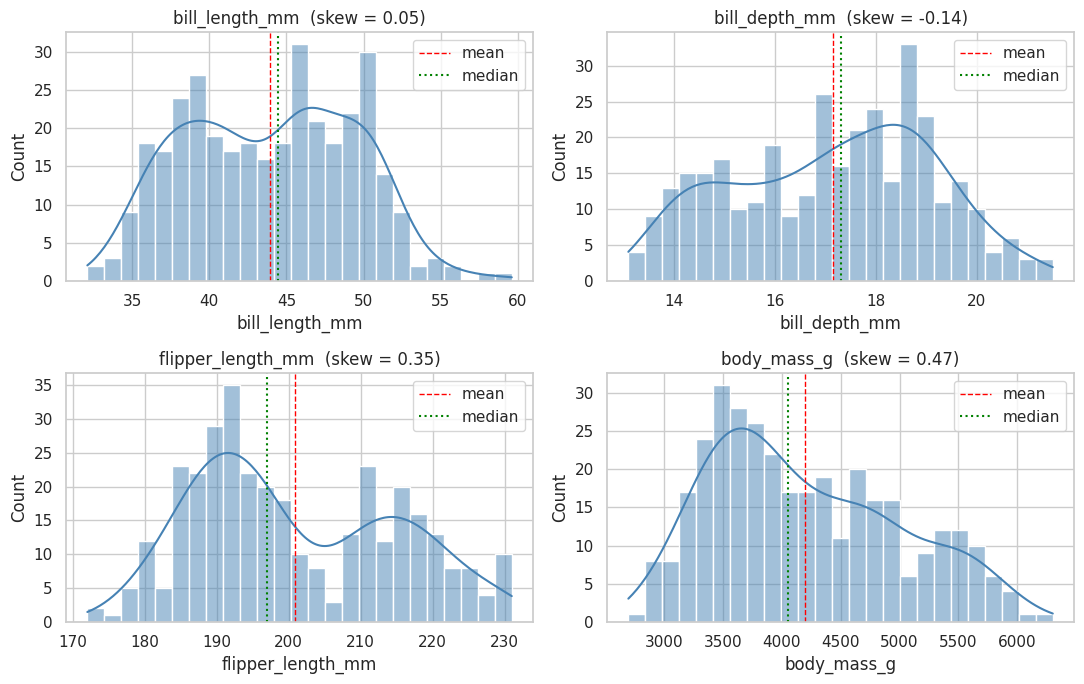

In [ ]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, bins=25, ax=ax, color="steelblue")
    ax.axvline(df[col].mean(), color="red", ls="--", lw=1, label="mean")
    ax.axvline(df[col].median(), color="green", ls=":", lw=1.5, label="median")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.legend()
plt.tight_layout()
plt.show()

**Reading:** several features look **bimodal or multi-modal** (notably `bill_length_mm` and `flipper_length_mm`).
That is a hint of hidden subgroups.

Skewness can be misleading here. `bill_length_mm` has a skew of 0.05, which suggests a symmetric shape, but the histogram is clearly two-humped. The two groups balance each other out, so the skew number hides the structure. That’s why the plot is worth looking at and not just the summary statistic!

The next plot colours the same histograms by species.

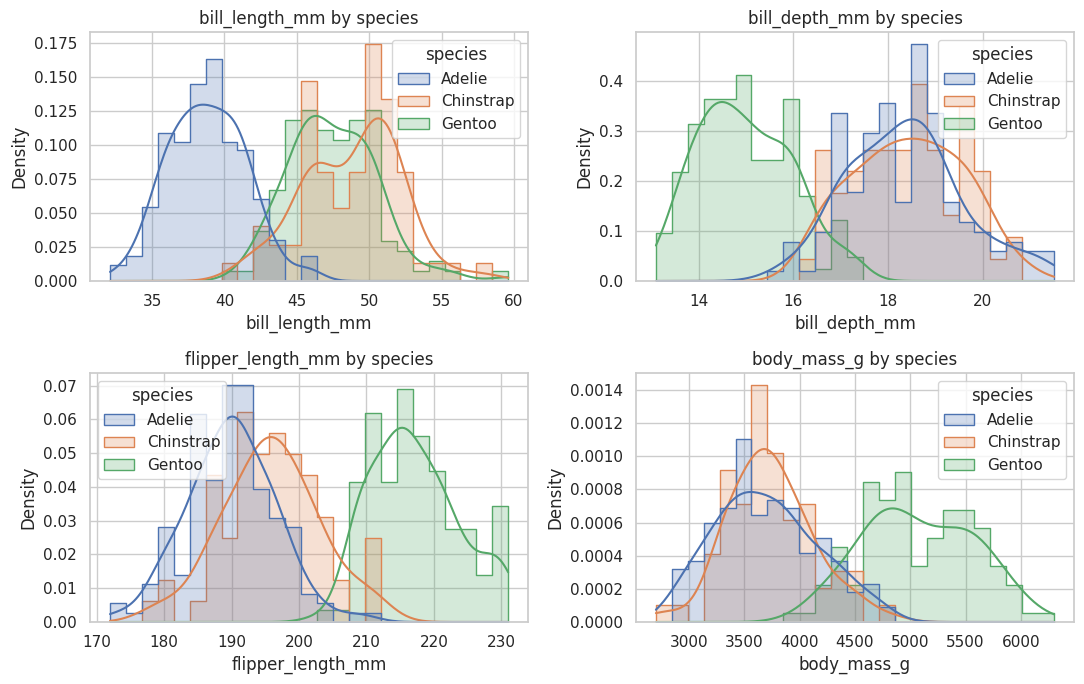

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="species", kde=True, bins=25, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(f"{col} by species")
plt.tight_layout()
plt.show()

Within each species the distributions are much closer to unimodal and roughly Gaussian (aka yehcbhou l la loi Normale). The multi-modality in the
pooled data is a **mixture** of species, which is the kind of signal that a classifier will exploit to make predictions.

## 4. Target distribution and relationships

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: count, dtype: float64


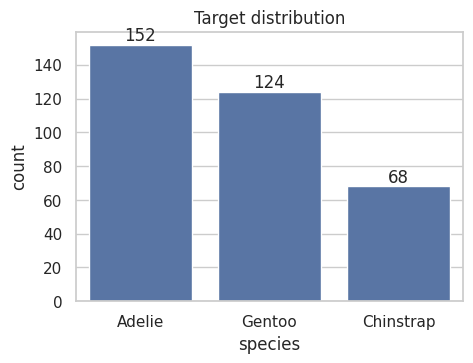

In [ ]:
counts = df["species"].value_counts()
print(counts)
print((counts / counts.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="species", order=counts.index, ax=ax)
ax.set_title("Target distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

**Class balance:** moderately imbalanced (Adelie is the majority, Chinstrap the minority). This is mild, but it
means (a) accuracy alone is a weak metric and (b) the train/test
split must be **stratified** by species.

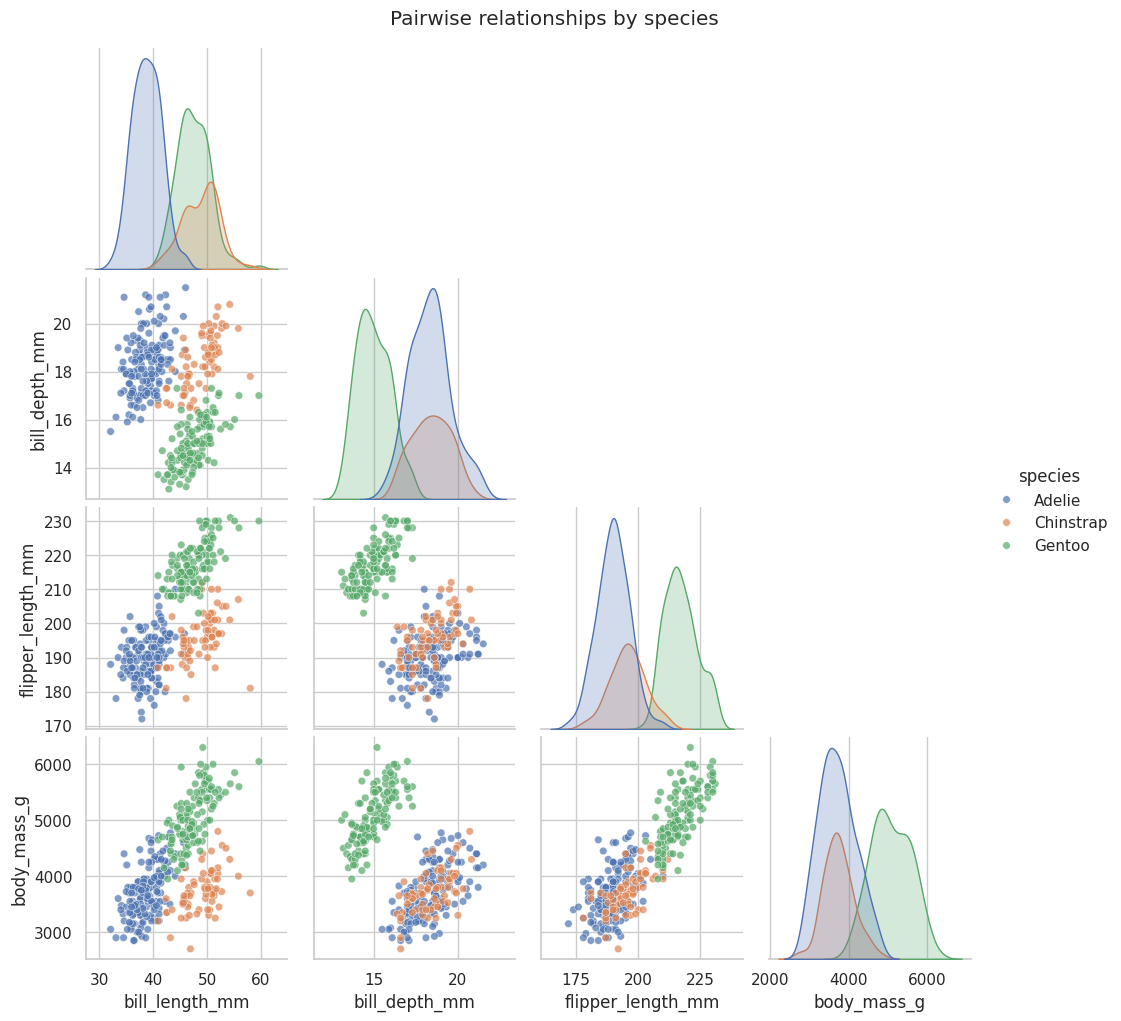

In [ ]:
sns.pairplot(df, vars=num_cols, hue="species", corner=True, plot_kws={"alpha": 0.7, "s": 30})
plt.suptitle("Pairwise relationships by species", y=1.02)
plt.show()

This grid shows every measurement against every other one, with each point being one penguin, colored by species.

**Diagonal panels:** smoothed histograms (like the blue curve before)
**Off-diagonal panels:** scatterplots of two measurements. Read the row label for the y-axis and the column label for the x-axis. Only the lower triangle is drawn because the upper half would just repeat it flipped.

Look for *how separated the colors are*. In `bill_depth` vs. `flipper_length`, **Gentoo** (green) sits in its own cluster, while **Adelie** and **Chinstrap** overlap heavily. In `bill_length` vs. `bill_depth`, all three species form fairly distinct clusters, so those two measurements together can tell all three species apart even though neither can alone.




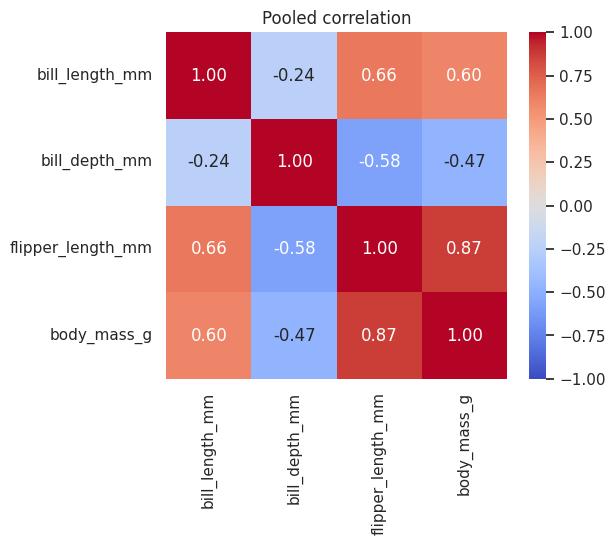

In [ ]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pooled correlation")
plt.show()

Each cell is the correlation between two measurements, from -1 to +1:

*   +1: they rise together perfectly
*   0: no linear relationship
*   -1: one rises as the other falls

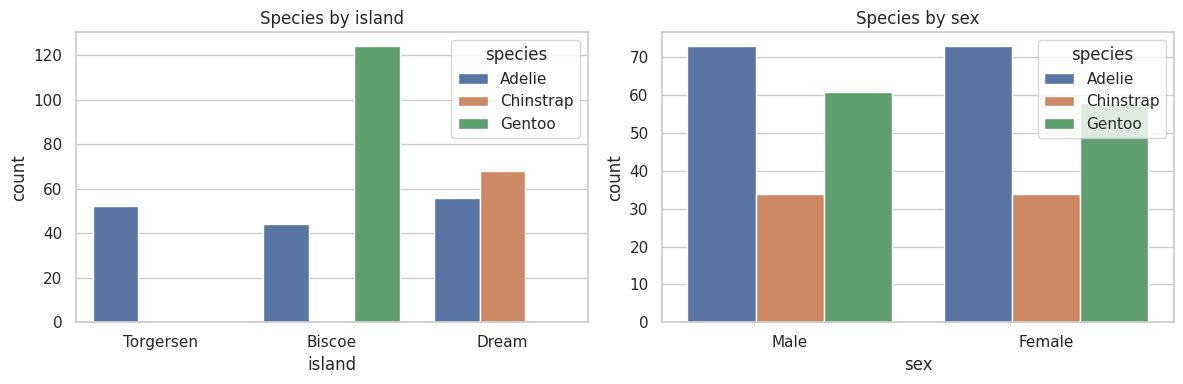

species    Adelie  Chinstrap  Gentoo  All
island                                   
Biscoe         44          0     124  168
Dream          56         68       0  124
Torgersen      52          0       0   52
All           152         68     124  344


In [ ]:
# Categorical relationships
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="island", hue="species", ax=axes[0])
axes[0].set_title("Species by island")
sns.countplot(data=df, x="sex", hue="species", ax=axes[1])
axes[1].set_title("Species by sex")
plt.tight_layout()
plt.show()

print(pd.crosstab(df["island"], df["species"], margins=True))

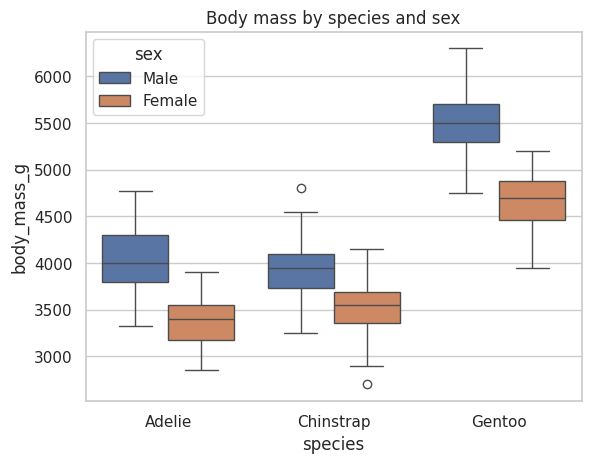

In [ ]:
# Sex is a strong driver of size within a species
sns.boxplot(data=df.dropna(subset=["sex"]), x="species", y="body_mass_g", hue="sex")
plt.title("Body mass by species and sex")
plt.show()

## 5. Outliers, sampling bias, leakage and data quality



### Outliers
Outliers should be judged **within the relevant group**: a 5 kg penguin is normal for a Gentoo but extreme for an
Adelie. We flag points using the 1.5×IQR rule *per species*.

In [ ]:
def iqr_outliers(frame, col, group="species", k=1.5):
    out = []
    for g, sub in frame.groupby(group):
        q1, q3 = sub[col].quantile([0.25, 0.75])
        lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
        out.append(sub[(sub[col] < lo) | (sub[col] > hi)])
    return pd.concat(out) if out else frame.iloc[0:0]

summary = {c: len(iqr_outliers(df, c)) for c in num_cols}
print("IQR outliers per column (within species):", summary)

flagged = pd.concat([iqr_outliers(df, c).assign(flag=c) for c in num_cols])
display(flagged)

IQR outliers per column (within species): {'bill_length_mm': 1, 'bill_depth_mm': 1, 'flipper_length_mm': 2, 'body_mass_g': 2}


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,flag
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male,bill_length_mm
19,Adelie,Torgersen,46.0,21.5,194.0,4200.0,Male,bill_depth_mm
28,Adelie,Biscoe,37.9,18.6,172.0,3150.0,Female,flipper_length_mm
129,Adelie,Torgersen,44.1,18.0,210.0,4000.0,Male,flipper_length_mm
189,Chinstrap,Dream,52.0,20.7,210.0,4800.0,Male,body_mass_g
190,Chinstrap,Dream,46.9,16.6,192.0,2700.0,Female,body_mass_g


**Reading:** a few points are flagged. Nothing here looks like a data-entry error
(negative values, impossible magnitudes). They are plausible biological variation, so the default decision is
to **keep them** and prefer models/scalers that are reasonably robust. Only remove a point if you can justify it
as an error, not because it is inconvenient.

### Sampling bias and representativeness

In [ ]:
print("Sex balance overall:")
print(df["sex"].value_counts(normalize=True, dropna=False).round(3))

print("\nSex balance within species:")
print(pd.crosstab(df["species"], df["sex"], normalize="index").round(3))

print("\nIsland composition per species:")
print(pd.crosstab(df["species"], df["island"], normalize="index").round(3))

Sex balance overall:
sex
Male      0.488
Female    0.480
NaN       0.032
Name: proportion, dtype: float64

Sex balance within species:
sex        Female   Male
species                 
Adelie      0.500  0.500
Chinstrap   0.500  0.500
Gentoo      0.487  0.513

Island composition per species:
island     Biscoe  Dream  Torgersen
species                            
Adelie      0.289  0.368      0.342
Chinstrap   0.000  1.000      0.000
Gentoo      1.000  0.000      0.000


**Points to note**
- **Confounding of `island` and `species`:** Gentoo appear on one island only and Chinstrap on one island only;
  Adelie appear on all three. Island is therefore **partly a proxy or substitute for species**.
- Sex is roughly balanced, but  remember `sex` is missing for a handful of rows.

### Data leakage
Leakage can either mean a feature that encodes the label in a way that should be unavailable at prediction time, (like `island`, not exactly leakage, but it is a *shortcut*: a model can score well on some species without learning the biology), or fitting
imputers, scalers or encoders on the *whole* dataset before splitting.

This following code compares two classifiers:
1. A baseline that always predicts the most frequent species.
2. A decision tree that predicts species using only the penguin's island.

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_all = df["species"]

baseline = cross_val_score(DummyClassifier(strategy="most_frequent"), np.zeros((len(df), 1)), y_all, cv=cv).mean()
island_only = cross_val_score(
    DecisionTreeClassifier(random_state=RANDOM_STATE), pd.get_dummies(df[["island"]]), y_all, cv=cv
).mean()
print(f"Majority-class baseline accuracy : {baseline:.3f}")
print(f"Island-only decision tree        : {island_only:.3f}")

Majority-class baseline accuracy : 0.442
Island-only decision tree        : 0.709


The island alone beats the majority baseline clearly, confirming it is an informative but **context-dependent
shortcut**. If the model will be deployed on penguins from other islands, evaluate with and without `island`.

### Data-quality checklist

In [ ]:
checks = {
    "negative measurements": int((df[num_cols] < 0).sum().sum()),
    "zero measurements": int((df[num_cols] == 0).sum().sum()),
    "unexpected `sex` labels": sorted(set(df["sex"].dropna().str.lower()) - {"male", "female"}),
    "leading/trailing whitespace in text columns": int(sum(
        (df[c].dropna().astype(str) != df[c].dropna().astype(str).str.strip()).sum() for c in ["species", "island", "sex"]
    )),
    "inconsistent case in species": df["species"].nunique() != df["species"].str.lower().nunique(),
}
for k, v in checks.items():
    print(f"{k:45s}: {v}")

negative measurements                        : 0
zero measurements                            : 0
unexpected `sex` labels                      : []
leading/trailing whitespace in text columns  : 0
inconsistent case in species                 : False


## 6. Conclusions we can use later

Motivations drawn from the EDA:

| Observation | Motivation |
|---|---|
| Measurements have different units/scales (mm vs g) | **Standardise** for scale-sensitive models (logistic regression, SVM, kNN) |
| `body_mass_g` is mildly right-skewed and varies strongly with size | Consider `log(body_mass)` for linear models |
| Species differ in *shape*, not just size | **Ratios** (bill length / depth) separate species better than raw values |
| `island`, `sex` are nominal | **One-hot encode** (no natural order) |
| Missing `sex` for a few rows | **Impute inside the pipeline** (most frequent), or add an "unknown" level |


## 8. Summary of findings

**Structure and quality**
- ~344 rows × 7 columns; 4 numeric measurements, 3 categorical columns.
- Missingness is small: a couple of rows with no measurements at all, and a few missing `sex` values.
- No meaningful duplicates, no impossible values.

**Distributions and relationships**
- Pooled distributions are multi-modal because of the species mixture; within-species they are close to Gaussian.
- Species are strongly separable in the measurement space (flipper length / body mass isolate Gentoo; bill
  length/depth separate Adelie from Chinstrap).

**Risks**
- Mild class imbalance → stratified splits, macro-F1.
- `island` is a partial proxy for `species` → report results with and without it.
- Small sample, single site → use cross-validation, avoid over-generalising.